# WHO Global Health Observatory Data Exploration

This notebook explores health data from the WHO GHO OData API for Sustainable Development Goals (SDGs).
* Reference: https://www.who.int/data/gho/info/gho-odata-api

In [1]:
# Import Required Libraries
import pandas as pd
import requests
import plotly.express as px
import plotly.graph_objects as go

# WHO GHO API Base URL
API_BASE_URL = "https://ghoapi.azureedge.net/api"

print("Libraries loaded successfully!")

Libraries loaded successfully!


## Fetching Available Dimensions

Dimensions are available in the WHO API.

In [2]:
# Fetch available dimensions
response = requests.get(f"{API_BASE_URL}/Dimension")
dimensions = pd.DataFrame(response.json()["value"])
print(f"Available Dimensions: {len(dimensions)}")
dimensions

Available Dimensions: 202


,Code,Title
0,ADVERTISINGTYPE,SUBSTANCE_ABUSE_ADVERTISING_TYPES
1,AGEGROUP,Age Group
2,ALCOHOLTYPE,Beverage Types
3,AMRGLASSCATEGORY,AMR GLASS Category
4,ANTIBIOTIC,Antibiotic
...,...,...
197,WPR_DATASOURCE,WPRO Data Source
198,WPR_DEMO_IND,WPRO Demo Indicator
199,WRS_OUTSIDE_REPORT,WRs from outside the region year report
200,WRS_STATUS,WHO Representative Status


## Fetching Countries List

Get the list of all countries available in the dataset.

In [3]:
# Fetch countries
response = requests.get(f"{API_BASE_URL}/DIMENSION/COUNTRY/DimensionValues")
countries = pd.DataFrame(response.json()["value"])
print(f"Total Countries: {len(countries)}")
countries[["Code", "Title"]].head(20)

Total Countries: 234


,Code,Title
0,ABW,Aruba
1,AFG,Afghanistan
2,AGO,Angola
3,AIA,Anguilla
4,ALB,Albania
5,AND,Andorra
6,ARE,United Arab Emirates
7,ARG,Argentina
8,ARM,Armenia
9,ASM,American Samoa


## 3. Fetch WHO Regions

In [4]:
# Fetch WHO regions
response = requests.get(f"{API_BASE_URL}/DIMENSION/REGION/DimensionValues")
regions = pd.DataFrame(response.json()["value"])
print(f"WHO Regions: {len(regions)}")
regions[["Code", "Title"]]

WHO Regions: 43


,Code,Title
0,AFR,Africa
1,AMR,Americas
2,EMR,Eastern Mediterranean
3,EUR,Europe
4,GBD_REG14_AFRD,"Africa region, stratum D (AFR D)"
5,GBD_REG14_AFRE,"Africa region, stratum E(AFR E)"
6,GBD_REG14_AMRA,"Americas region, stratum A (AMR A)"
7,GBD_REG14_AMRB,"Americas region, stratum B (AMR B)"
8,GBD_REG14_AMRD,"Americas region, stratum D (AMR D)"
9,GBD_REG14_EMRB,"Eastern Mediterranean region, stratum B (EMR B)"


## 4. Search for SDG Health Indicators

Let's search for indicators related to Sustainable Development Goals.

In [5]:
# Fetch all indicators (limited)
response = requests.get(f"{API_BASE_URL}/Indicator")
all_indicators = pd.DataFrame(response.json()["value"])
print(f"Total Indicators: {len(all_indicators)}")
all_indicators[["IndicatorCode", "IndicatorName"]].head(20)

Total Indicators: 3091


,IndicatorCode,IndicatorName
0,HIV_0000000001,Estimated number of people (all ages) living w...
1,HIV_0000000009,Reported number of people receiving antiretrov...
2,HCF_NO_ELECTRICITY,Percentage of health-care facilities with no a...
3,HIV_0000000006,Number of people dying from HIV-related causes
4,HIV_0000000011,Reported number of children receiving antiretr...
5,HIV_0000000012,Reported number of children receiving antiretr...
6,HIV_0000000020,Estimated number of pregnant women living with...
7,HIV_0000000021,Estimated number of pregnant women living with...
8,HIV_0000000026,Number of new HIV infections
9,HRH_06,Number of community health workers


In [6]:
# Search for SDG-related indicators
sdg_indicators = all_indicators[all_indicators["IndicatorName"].str.contains("SDG|mortality|life expectancy", case=False, na=False)]
print(f"SDG-related Indicators: {len(sdg_indicators)}")
sdg_indicators[["IndicatorCode", "IndicatorName"]].head(30)

SDG-related Indicators: 50


,IndicatorCode,IndicatorName
31,FINPROTECTION_CATA_TOT_10_LEVEL_MILLION,Population with household spending on health g...
32,FINPROTECTION_CATA_TOT_10_LEVEL_SH,Population with household spending on health g...
33,FINPROTECTION_CATA_TOT_10_POP,Population with household spending on health g...
34,FINPROTECTION_CATA_TOT_25_LEVEL_MILLION,Population with household spending on health g...
36,FINPROTECTION_CATA_TOT_25_LEVEL_SH,Population with household spending on health g...
115,imr,Infant mortality rate (deaths per 1000 live bi...
202,FINPROTECTION_CATA_TOT_25_POP,Population with household spending on health g...
305,CHILDMORT5TO14,Mortality rate for 5-14 year-olds (probability...
448,MDG_0000000007,Under-five mortality rate (probability of dyin...
489,MDG_0000000026,Maternal mortality ratio (per 100 000 live bir...


## 5. Fetch Life Expectancy Data

Let's fetch and explore Life Expectancy at Birth data.

In [7]:
# Fetch Life Expectancy data
indicator_code = "WHOSIS_000001"  # Life expectancy at birth
response = requests.get(f"{API_BASE_URL}/{indicator_code}")
life_expectancy = pd.DataFrame(response.json()["value"])

print(f"Records: {len(life_expectancy)}")
print(f"\nColumns: {life_expectancy.columns.tolist()}")
life_expectancy.head(10)

Records: 14112

Columns: ['Id', 'IndicatorCode', 'SpatialDimType', 'SpatialDim', 'TimeDimType', 'ParentLocationCode', 'ParentLocation', 'Dim1Type', 'Dim1', 'TimeDim', 'Dim2Type', 'Dim2', 'Dim3Type', 'Dim3', 'DataSourceDimType', 'DataSourceDim', 'Value', 'NumericValue', 'Low', 'High', 'Comments', 'Date', 'TimeDimensionValue', 'TimeDimensionBegin', 'TimeDimensionEnd']


,Id,IndicatorCode,SpatialDimType,SpatialDim,TimeDimType,ParentLocationCode,ParentLocation,Dim1Type,Dim1,TimeDim,...,DataSourceDim,Value,NumericValue,Low,High,Comments,Date,TimeDimensionValue,TimeDimensionBegin,TimeDimensionEnd
0,3387691,WHOSIS_000001,COUNTRY,SWZ,YEAR,AFR,Africa,SEX,SEX_MLE,2021,...,None,51.5 [48.8-54.3],51.5,48.8,54.3,None,2026-10-01T16:11:13.08+02:00,2021,2021-01-01T00:00:00+01:00,2021-12-31T00:00:00+01:00
1,3388090,WHOSIS_000001,COUNTRY,BFA,YEAR,AFR,Africa,SEX,SEX_BTSX,2017,...,None,62.2 [60-64.4],62.2,60.0,64.4,None,2026-10-01T16:11:13.08+02:00,2017,2017-01-01T00:00:00+01:00,2017-12-31T00:00:00+01:00
2,3391579,WHOSIS_000001,COUNTRY,DEU,YEAR,EUR,Europe,SEX,SEX_MLE,2008,...,None,77.4 [77.3-77.6],77.4,77.3,77.6,None,2026-10-01T16:11:13.08+02:00,2008,2008-01-01T00:00:00+01:00,2008-12-31T00:00:00+01:00
3,3391908,WHOSIS_000001,COUNTRY,IRL,YEAR,EUR,Europe,SEX,SEX_FMLE,2015,...,None,82.9 [82.5-83.4],82.9,82.5,83.4,None,2026-10-01T16:11:13.08+02:00,2015,2015-01-01T00:00:00+01:00,2015-12-31T00:00:00+01:00
4,3392773,WHOSIS_000001,WORLDBANKINCOMEGROUP,WB_UMI,YEAR,NaN,NaN,SEX,SEX_BTSX,2019,...,None,76.5 [75.6-77.5],76.5,75.6,77.5,None,2026-10-01T16:11:13.08+02:00,2019,2019-01-01T00:00:00+01:00,2019-12-31T00:00:00+01:00
5,3393034,WHOSIS_000001,COUNTRY,MLI,YEAR,AFR,Africa,SEX,SEX_MLE,2002,...,None,54.1 [51.5-56.9],54.1,51.5,56.9,None,2026-10-01T16:11:13.08+02:00,2002,2002-01-01T00:00:00+01:00,2002-12-31T00:00:00+01:00
6,3393246,WHOSIS_000001,COUNTRY,BEN,YEAR,AFR,Africa,SEX,SEX_BTSX,2008,...,None,60.4 [58-62.9],60.4,58.0,62.9,None,2026-10-01T16:11:13.08+02:00,2008,2008-01-01T00:00:00+01:00,2008-12-31T00:00:00+01:00
7,3393609,WHOSIS_000001,COUNTRY,CRI,YEAR,AMR,Americas,SEX,SEX_MLE,2006,...,None,76.1 [75.4-76.9],76.1,75.4,76.9,None,2026-10-01T16:11:13.08+02:00,2006,2006-01-01T00:00:00+01:00,2006-12-31T00:00:00+01:00
8,3393812,WHOSIS_000001,REGION,AFR,YEAR,NaN,NaN,SEX,SEX_MLE,2000,...,None,52.2 [49.6-54.8],52.2,49.6,54.8,None,2026-10-01T16:11:13.08+02:00,2000,2000-01-01T00:00:00+01:00,2000-12-31T00:00:00+01:00
9,3394119,WHOSIS_000001,COUNTRY,AUT,YEAR,EUR,Europe,SEX,SEX_FMLE,2007,...,None,82.6 [82.3-83],82.6,82.3,83.0,None,2026-10-01T16:11:13.08+02:00,2007,2007-01-01T00:00:00+01:00,2007-12-31T00:00:00+01:00


In [8]:
# Clean and process the data
life_exp_clean = life_expectancy[["SpatialDim", "TimeDim", "Dim1", "NumericValue"]].copy()
life_exp_clean.columns = ["Country", "Year", "Sex", "LifeExpectancy"]
life_exp_clean["Year"] = pd.to_numeric(life_exp_clean["Year"], errors="coerce")
life_exp_clean["LifeExpectancy"] = pd.to_numeric(life_exp_clean["LifeExpectancy"], errors="coerce")
life_exp_clean = life_exp_clean.dropna()

print(f"Cleaned Records: {len(life_exp_clean)}")
print(f"Year Range: {life_exp_clean['Year'].min():.0f} - {life_exp_clean['Year'].max():.0f}")
print(f"Countries: {life_exp_clean['Country'].nunique()}")
life_exp_clean.head(10)

Cleaned Records: 14112
Year Range: 2000 - 2023
Countries: 196


,Country,Year,Sex,LifeExpectancy
0,SWZ,2021,SEX_MLE,51.5
1,BFA,2017,SEX_BTSX,62.2
2,DEU,2008,SEX_MLE,77.4
3,IRL,2015,SEX_FMLE,82.9
4,WB_UMI,2019,SEX_BTSX,76.5
5,MLI,2002,SEX_MLE,54.1
6,BEN,2008,SEX_BTSX,60.4
7,CRI,2006,SEX_MLE,76.1
8,AFR,2000,SEX_MLE,52.2
9,AUT,2007,SEX_FMLE,82.6


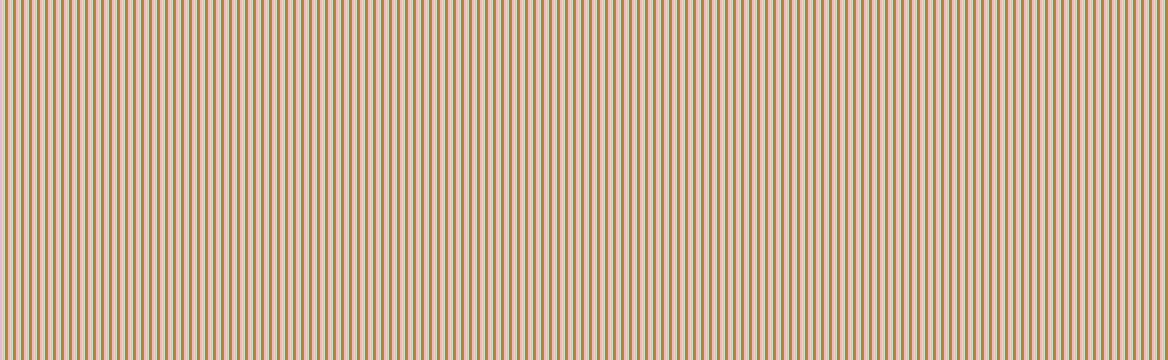

In [17]:
# Visualize Life Expectancy by Year (Global Average)
global_avg = life_exp_clean.groupby(["Year", "Sex"])["LifeExpectancy"].mean().reset_index()

fig = px.line(global_avg, x="Year", y="LifeExpectancy", color="Sex",
              title="Global Average Life Expectancy at Birth by Sex",
              labels={"LifeExpectancy": "Life Expectancy (years)"})
fig.update_layout(template="plotly_white")
fig.show()

## Maternal Mortality Data (SDG 3.1)

In [10]:
# Fetch Maternal Mortality data
indicator_code = "MDG_0000000001"  # Maternal mortality ratio
response = requests.get(f"{API_BASE_URL}/{indicator_code}")
maternal_mortality = pd.DataFrame(response.json()["value"])

print(f"Maternal Mortality Records: {len(maternal_mortality)}")
maternal_mortality.head()

Maternal Mortality Records: 44424


,Id,IndicatorCode,SpatialDimType,SpatialDim,TimeDimType,ParentLocationCode,ParentLocation,Dim1Type,TimeDim,Dim1,...,DataSourceDim,Value,NumericValue,Low,High,Comments,Date,TimeDimensionValue,TimeDimensionBegin,TimeDimensionEnd
0,3387569,MDG_0000000001,COUNTRY,GEO,YEAR,EUR,Europe,SEX,1987,SEX_FMLE,...,None,34.8 [30.4-40.0],34.800877,30.357056,39.965334,NaN,2026-08-04T15:40:44.863+02:00,1987,1987-01-01T00:00:00+01:00,1987-12-31T00:00:00+01:00
1,3387652,MDG_0000000001,COUNTRY,DMA,YEAR,AMR,Americas,SEX,2005,SEX_MLE,...,None,20.2 [18.7-21.9],20.233193,18.653766,21.919670,NaN,2026-08-04T15:40:44.863+02:00,2005,2005-01-01T00:00:00+01:00,2005-12-31T00:00:00+01:00
2,3387705,MDG_0000000001,COUNTRY,KOR,YEAR,WPR,Western Pacific,SEX,2020,SEX_MLE,...,None,2.8 [2.7-2.8],2.756589,2.672575,2.842874,NaN,2026-08-04T15:40:44.863+02:00,2020,2020-01-01T00:00:00+01:00,2020-12-31T00:00:00+01:00
3,3387757,MDG_0000000001,COUNTRY,NPL,YEAR,SEAR,South-East Asia,SEX,1996,SEX_MLE,...,None,80.7 [75.5-86.5],80.704043,75.474092,86.458062,NaN,2026-08-04T15:40:44.863+02:00,1996,1996-01-01T00:00:00+01:00,1996-12-31T00:00:00+01:00
4,3387761,MDG_0000000001,COUNTRY,IRQ,YEAR,EMR,Eastern Mediterranean,SEX,1985,SEX_MLE,...,None,53.1 [47.9-58.8],53.149794,47.914122,58.791698,NaN,2026-08-04T15:40:44.863+02:00,1985,1985-01-01T00:00:00+01:00,1985-12-31T00:00:00+01:00


In [11]:
# Process maternal mortality data
mm_clean = maternal_mortality[["SpatialDim", "TimeDim", "NumericValue"]].copy()
mm_clean.columns = ["Country", "Year", "MaternalMortalityRatio"]
mm_clean["Year"] = pd.to_numeric(mm_clean["Year"], errors="coerce")
mm_clean["MaternalMortalityRatio"] = pd.to_numeric(mm_clean["MaternalMortalityRatio"], errors="coerce")
mm_clean = mm_clean.dropna()

# Get latest year data
latest_year = mm_clean["Year"].max()
mm_latest = mm_clean[mm_clean["Year"] == latest_year].sort_values("MaternalMortalityRatio", ascending=False)

print(f"Latest Year: {latest_year:.0f}")
print(f"\nTop 10 Countries with Highest Maternal Mortality:")
mm_latest.head(10)

Latest Year: 2024

Top 10 Countries with Highest Maternal Mortality:


,Country,Year,MaternalMortalityRatio
6677,SSD,2024,77.327388
6572,NGA,2024,76.017244
6675,SSD,2024,71.869663
6569,NER,2024,70.578149
6671,SOM,2024,70.568400
6570,NGA,2024,69.771281
6434,LBR,2024,69.626464
6918,ZWE,2024,68.593673
6676,SSD,2024,66.083487
6332,GIN,2024,66.043225


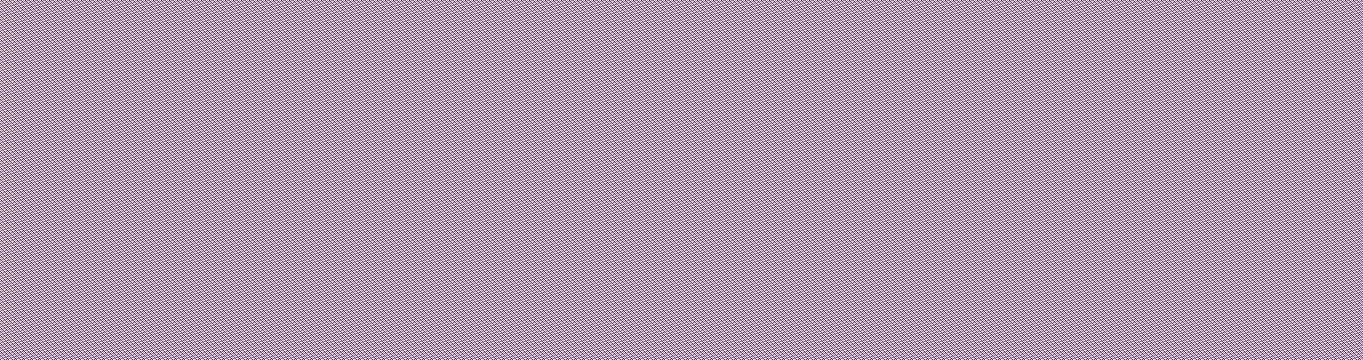

In [12]:
# Visualize Maternal Mortality on World Map
fig = px.choropleth(mm_latest, 
                    locations="Country",
                    color="MaternalMortalityRatio",
                    hover_name="Country",
                    color_continuous_scale="Reds",
                    title=f"Maternal Mortality Ratio per 100,000 Live Births ({latest_year:.0f})")
fig.update_layout(geo=dict(showframe=False, projection_type="natural earth"))
fig.show()

## 7. Fetch Under-5 Mortality Data (SDG 3.2)

In [13]:
# Fetch Under-5 Mortality data
indicator_code = "MDG_0000000007"  # Under-five mortality rate
response = requests.get(f"{API_BASE_URL}/{indicator_code}")
under5_mortality = pd.DataFrame(response.json()["value"])

# Process data
u5_clean = under5_mortality[["SpatialDim", "TimeDim", "NumericValue"]].copy()
u5_clean.columns = ["Country", "Year", "Under5MortalityRate"]
u5_clean["Year"] = pd.to_numeric(u5_clean["Year"], errors="coerce")
u5_clean["Under5MortalityRate"] = pd.to_numeric(u5_clean["Under5MortalityRate"], errors="coerce")
u5_clean = u5_clean.dropna()

print(f"Under-5 Mortality Records: {len(u5_clean)}")
u5_clean.head(10)

Under-5 Mortality Records: 64510


,Country,Year,Under5MortalityRate
0,GNQ,2022,78.248870
1,KEN,1953,283.619094
2,KEN,2018,51.074248
3,MDA,2004,23.925273
4,THA,2009,12.209748
5,JPN,2016,2.673006
6,SLV,1980,120.046700
7,SSD,1991,297.574393
8,NIC,1983,95.165025
9,BDI,2021,52.269643


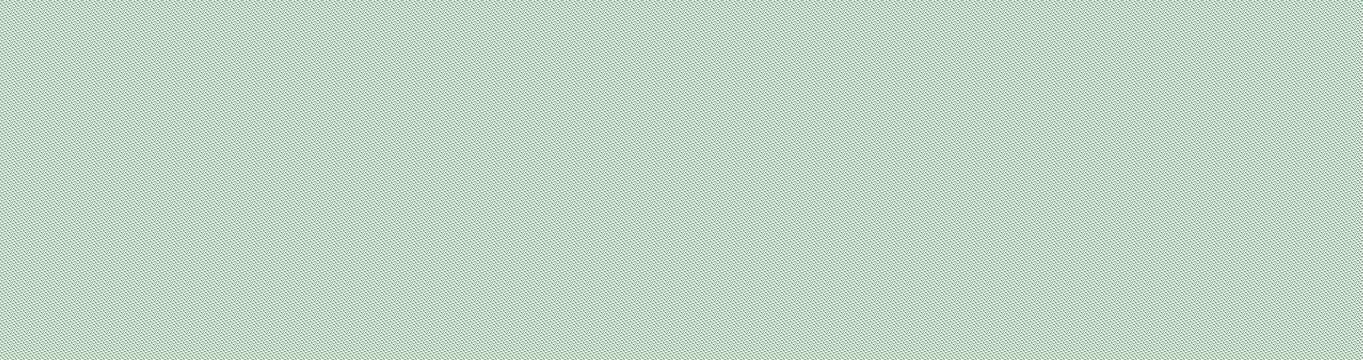

In [14]:
# Global trend of Under-5 Mortality
u5_trend = u5_clean.groupby("Year")["Under5MortalityRate"].mean().reset_index()

fig = px.line(u5_trend, x="Year", y="Under5MortalityRate",
              title="Global Average Under-5 Mortality Rate (per 1,000 live births)",
              markers=True)
fig.update_layout(template="plotly_white")
fig.show()

## 8. Fetch UHC Service Coverage Index (SDG 3.8)

In [15]:
# Fetch UHC Service Coverage data
indicator_code = "UHC_INDEX_REPORTED"  # UHC service coverage index
response = requests.get(f"{API_BASE_URL}/{indicator_code}")
uhc_data = pd.DataFrame(response.json()["value"])

# Process data
uhc_clean = uhc_data[["SpatialDim", "TimeDim", "NumericValue"]].copy()
uhc_clean.columns = ["Country", "Year", "UHC_Index"]
uhc_clean["Year"] = pd.to_numeric(uhc_clean["Year"], errors="coerce")
uhc_clean["UHC_Index"] = pd.to_numeric(uhc_clean["UHC_Index"], errors="coerce")
uhc_clean = uhc_clean.dropna()

print(f"UHC Index Records: {len(uhc_clean)}")
uhc_clean.describe()

UHC Index Records: 5160


,Year,UHC_Index
count,5160.000000,5160.000000
mean,2011.500000,62.979070
std,6.922857,18.219238
min,2000.000000,13.000000
25%,2005.750000,49.000000
50%,2011.500000,68.000000
75%,2017.250000,78.000000
max,2023.000000,92.000000


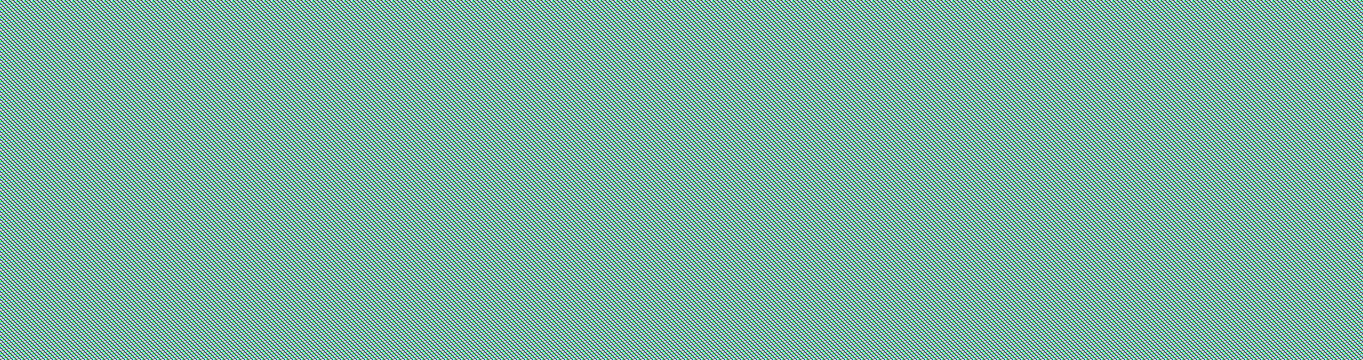

In [16]:
# Distribution of UHC Index (latest year)
latest_year = uhc_clean["Year"].max()
uhc_latest = uhc_clean[uhc_clean["Year"] == latest_year]

fig = px.histogram(uhc_latest, x="UHC_Index", nbins=30,
                   title=f"Distribution of UHC Service Coverage Index ({latest_year:.0f})",
                   labels={"UHC_Index": "UHC Index (0-100)"})
fig.update_layout(template="plotly_white")
fig.show()

## 9. Summary Statistics

In [ ]:
# Create a summary of all fetched data
summary = {
    "Dataset": ["Life Expectancy", "Maternal Mortality", "Under-5 Mortality", "UHC Index"],
    "Records": [len(life_exp_clean), len(mm_clean), len(u5_clean), len(uhc_clean)],
    "Countries": [life_exp_clean["Country"].nunique(), mm_clean["Country"].nunique(), 
                  u5_clean["Country"].nunique(), uhc_clean["Country"].nunique()],
    "Year Range": [
        f"{life_exp_clean['Year'].min():.0f}-{life_exp_clean['Year'].max():.0f}",
        f"{mm_clean['Year'].min():.0f}-{mm_clean['Year'].max():.0f}",
        f"{u5_clean['Year'].min():.0f}-{u5_clean['Year'].max():.0f}",
        f"{uhc_clean['Year'].min():.0f}-{uhc_clean['Year'].max():.0f}"
    ]
}

summary_df = pd.DataFrame(summary)
print("📊 Data Summary")
print("="*50)
summary_df

## 10. Export Data to CSV

In [ ]:
# Export cleaned datasets to CSV files
life_exp_clean.to_csv("life_expectancy_data.csv", index=False)
mm_clean.to_csv("maternal_mortality_data.csv", index=False)
u5_clean.to_csv("under5_mortality_data.csv", index=False)
uhc_clean.to_csv("uhc_index_data.csv", index=False)

print("✅ Data exported successfully!")
print("- life_expectancy_data.csv")
print("- maternal_mortality_data.csv")
print("- under5_mortality_data.csv")
print("- uhc_index_data.csv")